# Results

This notebook presents what the pipeline found: how far the model's fraud probabilities can be
trusted, which approve/decline threshold each Visa VAMP cap allows, and what each of those
policies earns a payment provider under two common pricing models.

The work behind it is done by the five pipeline stages, which must have run first. They load the
590,540 labelled IEEE-CIS transactions into DuckDB, build the features in SQL, split the six
months chronologically, train LightGBM on the first 131 days, calibrate its scores on the next
21, and score the final 31 days, the evaluation window. The last stage then tries every
possible threshold on that window and writes the chosen policies to a small data mart. Every
number below is read from those two databases, opened read-only: nothing is retrained or
written back.

In [16]:
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
from matplotlib.ticker import FixedLocator, FuncFormatter, NullLocator

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config.yaml").exists())
con = duckdb.connect(str(ROOT / "data" / "raw" / "fraud.duckdb"), read_only=True)
con.execute(f"ATTACH IF NOT EXISTS '{ROOT / 'data' / 'mart.duckdb'}' AS mart (READ_ONLY)");

The trade-off curve and the net-revenue chart are also saved to `figures/`, for the README.

## Calibration

A threshold on a probability is only meaningful if the probability means what it says. LightGBM
ranks transactions well, but its raw scores are not fraud rates, so the training stage fits an
isotonic calibration on the 21 days that follow training and applies it to the evaluation
window. 

We want to check the result with a reliability diagram: the window is cut into ten equal-width
bins of predicted probability, and each bin's average prediction is plotted against the share
of its transactions that turned out to be fraud. A perfectly calibrated model lies on the
diagonal.

In [19]:
BINS = 10

bins = con.execute("""
    SELECT least(floor(p.p_fraud * $bins), $bins - 1) AS bin, count(*) AS n,
           avg(p.p_fraud) AS predicted, avg(e.isFraud) AS observed
    FROM predictions p JOIN eval_set e USING (TransactionID)
    GROUP BY 1 ORDER BY 1
""", {"bins": BINS}).df()
mean_predicted = (bins.predicted * bins.n).sum() / bins.n.sum()
observed = (bins.observed * bins.n).sum() / bins.n.sum()

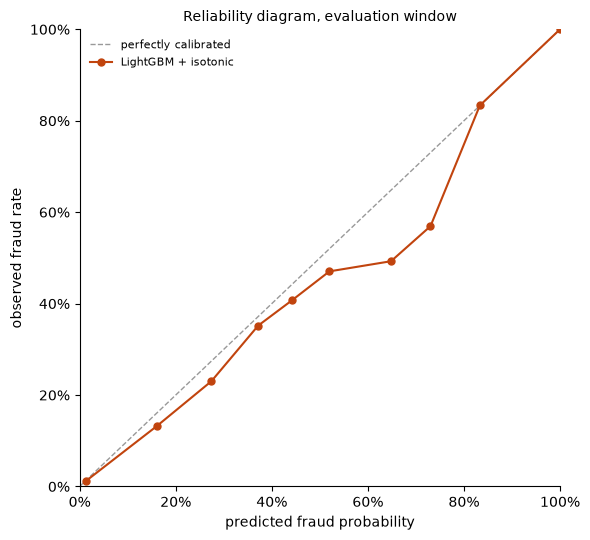

In [20]:
pct = FuncFormatter(lambda v, _: f"{v:.0%}")
fig, ax = plt.subplots(figsize=(6, 5.5))
ax.plot([0, 1], [0, 1], ls="--", lw=1, color="#999", label="perfectly calibrated")
ax.plot(bins.predicted, bins.observed, "o-", ms=5, lw=1.5, color="#c1440e",
        label="LightGBM + isotonic")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.xaxis.set_major_formatter(pct)
ax.yaxis.set_major_formatter(pct)
ax.set_xlabel("predicted fraud probability")
ax.set_ylabel("observed fraud rate")
ax.set_title("Reliability diagram, evaluation window", fontsize=10)
ax.legend(fontsize=8, frameon=False, loc="upper left")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()

Over the whole window the model predicts 3.80% fraud against 3.45% observed. Most transactions
sit in the lowest bin, where the curve hugs the diagonal; in the middle bins it falls below it,
so the model over-predicts there. For a payment provider that is the safer error, since it
overstates risk rather than hiding it, but it has a cost: the predicted fraud ratio is what the
provider watches before chargebacks arrive, and over-prediction makes it run ahead of the real
one.

## The run's results

Each time the policy stage runs, it stores one row per VAMP cap and pricing scenario in the
mart, tagged with the model run that produced the probabilities. The cell below loads the rows
for the run currently in the database, so that every section describes the same model.

In [17]:
thresholds = con.execute((ROOT / "notebooks" / "thresholds.sql").read_text()).df()

Each row holds:
- The chosen threshold;
- What it approves;
- Its realised and predicted fraud ratio;
- The VAMP events and fees it incurs;
- Its revenue at that scenario's take rate.

The two scenarios are two pricing models, whose sourced net take rates bracket the market:

- **Interchange++, 16.7 bps.** Adyen's net take rate in Q2 2025, on a mostly enterprise book
  where interchange and scheme fees are passed through at cost.
- **Blended, about 36 bps.** Stripe's 2025 revenue over its total volume, on a mostly
  flat-rate book of small and mid-sized merchants. It includes non-payment products, so it
  reads high for payments alone.

## Trade-off curve

The policy stage sorts the evaluation window by calibrated probability and evaluates every
policy of the form "approve everything below t": 153 candidate thresholds, one per distinct
probability the calibration produces. For each it records what would have been approved and how
much of it turned out to be fraud.

In [21]:
curve = con.execute("SELECT * FROM policy_curve ORDER BY threshold").df()
points = thresholds.drop_duplicates("cap")

The curve shows the trade-off this creates. Moving right, the threshold rises: more value is
approved, and the fraud ratio of approved traffic, the quantity VAMP caps, climbs with it. The
solid line is the realised ratio, known only once chargebacks have matured; the dashed line is
the predicted ratio, the mean probability of what was approved, which the provider can see on
the day. The marked points are the highest thresholds that keep each cap.

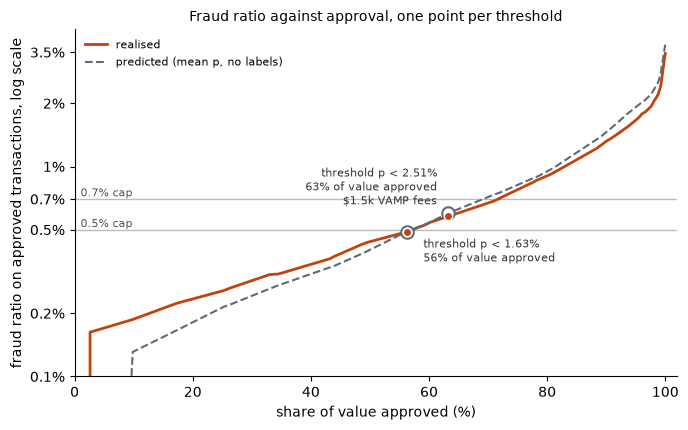

In [22]:
everything = curve.iloc[-1]
total = everything.legit_value + everything.fraud_value
share = lambda d: (d.legit_value + d.fraud_value) / total * 100
fig, ax = plt.subplots(figsize=(7, 4.4))
ax.plot(share(curve), curve.fraud_ratio * 100, lw=2, color="#c1440e", label="realised")
ax.plot(share(curve), curve.expected_ratio * 100, lw=1.5, ls="--", color="#5b6b7a",
        label="predicted (mean p, no labels)")
# Tightest cap labelled below the curve, the rest above, so neighbours never overlap.
offsets = [(12, -4, "left", "top")] + [(-8, 6, "right", "bottom")] * (len(points) - 1)
for r, (dx, dy, ha, va) in zip(points.itertuples(), offsets):
    approved = r.value_share * 100
    ax.axhline(r.cap * 100, color="#bbb", lw=1, zorder=0)
    ax.text(1, r.cap * 100, f"{r.cap:.1%} cap", va="bottom", fontsize=8, color="#555")
    ax.plot(approved, r.expected_ratio * 100, "o", ms=9, mfc="white", mec="#5b6b7a",
            mew=1.5, zorder=3)
    ax.plot(approved, r.fraud_ratio * 100, "o", ms=6, color="#c1440e", mec="white", mew=1,
            zorder=4)
    fees = "\n" + rf"\${r.vamp_fees / 1e3:,.1f}k VAMP fees" if r.vamp_fees else ""
    ax.annotate(f"threshold p < {r.threshold:.2%}\n{approved:.0f}% of value approved{fees}",
                (approved, r.fraud_ratio * 100), xytext=(dx, dy), ha=ha, va=va,
                textcoords="offset points", fontsize=8, color="#333")
ax.set_xlabel("share of value approved (%)")
ax.set_ylabel("fraud ratio on approved transactions, log scale")
ax.set_title("Fraud ratio against approval, one point per threshold", fontsize=10)
ax.set_xlim(0, 102)
# Isotonic gives the safest step p = 0, so the predicted line starts below the axis.
ax.set_yscale("log")
ax.set_ylim(0.1, 4.5)
ax.yaxis.set_major_locator(FixedLocator([0.1, 0.2, 0.5, 0.7, 1, 2, 3.5]))
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}%"))
ax.yaxis.set_minor_locator(NullLocator())
ax.spines[["top", "right"]].set_visible(False)
ax.legend(fontsize=8, frameon=False, loc="upper left")
fig.tight_layout()
fig.savefig(ROOT / "notebooks" / "figures" / "tradeoff_curve.png", dpi=150)

At the 0.5% cap the provider approves 56% of the value; the 0.7% cap lifts that to 63%, but
every approved fraud then pays Visa a fee. The 0.7% threshold is also held down by the predicted
ratio: the next threshold up would keep the realised ratio under 0.7% but push the predicted one
over it, and a provider cannot knowingly run that policy.

## Chosen thresholds

The table below is the policy stage's record of the two policies, as stored in the mart. It has
four rows because each cap is priced under both pricing models: the two rows of a cap describe
the same policy and are identical up to `vamp_fees`; only the columns from `scenario` onwards
change. The columns read as follows:

- `cap`: the VAMP ratio the policy must stay under, 0.5% (Visa's Above Standard line) or 0.7%
  (its Excessive line).
- `threshold`: the calibrated fraud probability below which a transaction is approved; anything
  scored at or above it is declined.
- `approved_share` and `value_share`: the share of the window's 89,614 transactions, and of
  their dollar value, that the policy approves.
- `fraud_ratio`: the VAMP ratio the policy actually produced, approved frauds over approved
  transactions, once every label is known.
- `expected_ratio`: the ratio the provider would have predicted on the day, the mean fraud
  probability of the transactions it approved.
- `vamp_events` and `vamp_fees`: the approved frauds, each of which Visa counts as one event,
  and the fees Visa charges on them.
- `take_rate`, `revenue` and `net_revenue`: the provider's fee on each approved legitimate
  dollar, the revenue it brings, and that revenue after VAMP fees.
- `forgone`: the revenue the declined legitimate transactions would have brought.

In [23]:
thresholds

,cap,threshold,approved_share,value_share,fraud_ratio,expected_ratio,vamp_events,vamp_fees,scenario,take_rate,revenue,net_revenue,forgone
0,0.005,0.016347,0.687370,0.562282,0.004887,0.004901,301,0.0,interchange_plus,0.00167,11457.539128,11457.539128,8248.892696
1,0.005,0.016347,0.687370,0.562282,0.004887,0.004901,301,0.0,blended,0.00360,24698.886743,24698.886743,17782.044134
2,0.007,0.025078,0.744527,0.632480,0.005785,0.005990,386,1544.0,interchange_plus,0.00167,12871.694109,11327.694109,6834.737714
3,0.007,0.025078,0.744527,0.632480,0.005785,0.005990,386,1544.0,blended,0.00360,27747.364547,26203.364547,14733.566330


**Under the 0.5% cap** the provider approves every transaction scored below 1.63%: 61,598
transactions, 68.7% of the window, carrying 56.2% of its value. 301 of them turn out to be
fraud, a realised ratio of 0.49%, just under the cap. The predicted ratio is also 0.49%, so at
these low probabilities the calibration is accurate and the provider would have seen the right
number on the day. With the ratio under 0.5% no VAMP fee is due, and net revenue equals
revenue: $11,458 at 16.7 bps and $24,699 at 36 bps. 

**Under the 0.7% cap** the threshold rises to 2.51%. There is a realised fraud ratio of 0.58% against a predicted
0.60%. Both sit well below 0.7%: as the trade-off curve showed, the threshold is stopped by the
predicted ratio, not the realised one. The portfolio falls in the Above Standard band though, so each event pays Visa $4. That is
$1,544, the same under both pricing models.

Under both caps the transactions the model
declines are larger, on average, than those it approves. Moving from the first policy to the
second approves 5,122 more transactions, 85 of them fraud.
The next two sections ask whether that trade pays.

## Inside the Above Standard band

The threshold rule picks the highest threshold under each cap, which approves the most
legitimate value and so earns the most gross revenue. Under 0.5% that is also the best net
result, since no fee applies. Under 0.7% it need not be, and the reason is in how net revenue
is built. At any threshold, with take rate $r$ and a fee $f$ per VAMP event:

$$\text{net revenue} = r \times \text{approved legitimate value} - f \times \text{approved frauds}$$

A fraud earns nothing, because the sale is reversed, so only legitimate value is paid; and
every approved fraud is one event. Inside the Above Standard band the realised fraud ratio stays
between 0.5% and 0.7%, so $f$ is the same \$4 at every threshold. Raising the threshold by one
isotonic step adds $\Delta L$ of legitimate value and $\Delta F$ frauds, and changes net revenue by

$$\Delta\text{net} = r\,\Delta L - f\,\Delta F$$

The step pays when $\Delta\text{net} > 0$. Dividing by $r\,\Delta F$ gives two equivalent
readings:
- per fraud, $\Delta L / \Delta F > f / r$: the step must bring more than `fee / take_rate` of
  legitimate value with each fraud, so \$2,395 at 16.7 bps and \$1,111 at 36 bps;
- per take rate, $r > f\,\Delta F / \Delta L$: the take rate must exceed the step's
  `min_take_rate`.

If every step in the band pays, net revenue rises at each one, and the highest threshold is
also the best paid. If a step fails, a lower threshold can earn more.

Two kinds of step fall outside the formula. A step that adds no fraud ($\Delta F = 0$) always
pays, since it adds legitimate value only. And the step from the 0.5% threshold into the band
is not like the others: crossing 0.5% switches the fee on for every event already approved,
not only the new ones. That step is the choice between the two caps, which the last section
prices.

`band_steps.sql` walks the trade-off curve from the first threshold whose realised ratio passes
0.5% up to the chosen 0.7% policy, and keeps each step that adds at least one fraud. For
each it gives:
- the threshold the step reaches;
- the frauds and legitimate value it adds, and the legitimate value per fraud;
- `min_take_rate`, $f\,\Delta F / \Delta L$.

In [24]:
steps = con.execute((ROOT / "notebooks" / "band_steps.sql").read_text()).df()
rates = ", ".join(f"{r * 1e4:.1f}" for r in sorted(thresholds.take_rate.unique()))
print(f"top of the band is best paid above {steps.min_take_rate.max() * 1e4:.1f} bps; "
      f"scenarios: {rates} bps")
steps

top of the band is best paid above 5.1 bps; scenarios: 16.7, 36.0 bps


,cap,threshold,extra_frauds,extra_legit_value,legit_per_fraud,min_take_rate
0,0.007,0.022096,14.0,108832.216,7773.729714,0.000515
1,0.007,0.024114,35.0,356482.338,10185.209657,0.000393


The band holds 15 thresholds, so 14 steps lead up to the chosen one. Twelve of them add
legitimate value alone and always pay. The two that add fraud:
- Raising the threshold to 2.21% adds 14 frauds and \$108,832 of legitimate value, \$7,774 per
  fraud. It would lose money below 5.1 bps.
- Raising it to 2.41% adds 35 frauds and \$356,482, \$10,185 per fraud. It would lose money
  below 3.9 bps.

The last step, up to the chosen 2.51%, adds no fraud. Both pricing models, being based on take rates equal to 16.7 and 36 bps, sit far above 5.1bps, so every step up pays for its fees, and pushing up until we are close to the 0.7% ceiling is also the best paid one inside the band. This holds for any take rate above 5.1 bps; a
provider earning less would do better to stop lower.

The same rule is checked in `tests/test_policy_economics.py`, against a brute-force search
for the best net revenue inside a band: on a synthetic sample where every step pays, the
highest threshold is the best paid, and where one step fails, a lower threshold wins.

## Two pricing models

The previous sections fixed the two policies. This one asks which of them the provider should
run. The answer depends on what the provider charges, because gross revenue derives from the take rate applied on
approved legitimate value: 16.7 bps under Interchange++ and about 36 bps under blended pricing,
the two scenarios introduced with the run's results.

Moving from the 0.5% to the 0.7% policy adds \$846,799 of approved legitimate value and \$1,544
of VAMP fees. The extra revenue scales with the take rate and the fees do not, so there is one
take rate at which they are equal: the break-even, \$1,544 / \$846,799. It depends not depend on either scenario. The cell below computes it from the table.

In [25]:
lo, hi = (thresholds[thresholds.cap == c].iloc[0] for c in sorted(thresholds.cap.unique()))
breakeven = (hi.vamp_fees - lo.vamp_fees) / ((hi.revenue - lo.revenue) / hi.take_rate)

The following chart compares net revenue after VAMP fees, on the evaluation window, for the two policies
under each pricing model:
- Each row is a pricing model.
- The left bubble is the policy under the 0.5% cap, the right one the policy under the 0.7% cap.
- Bubble size follows net revenue, and the better-paid policy sits higher, with its value in
  bold.
- The figure between the two bubbles is the difference.

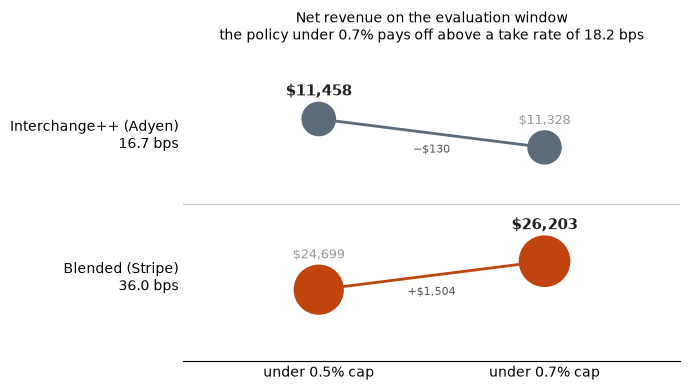

In [26]:
names = {"interchange_plus": "Interchange++ (Adyen)", "blended": "Blended (Stripe)"}
colors = {"interchange_plus": "#5b6b7a", "blended": "#c1440e"}
caps = sorted(thresholds.cap.unique())
rows = thresholds.drop_duplicates("scenario").sort_values("take_rate", ascending=False)
fig, ax = plt.subplots(figsize=(7, 4))
for y, s in enumerate(rows.itertuples()):
    g = thresholds[thresholds.scenario == s.scenario].sort_values("cap")
    x = [caps.index(c) for c in g.cap]
    # The better-paid cap sits higher in its band, so each line slopes towards the winner.
    ys = [y + (0.1 if v == g.net_revenue.max() else -0.1) for v in g.net_revenue]
    ax.plot(x, ys, lw=2, color=colors[s.scenario], zorder=1)
    size = g.net_revenue / 20
    ax.scatter(x, ys, s=size, color=colors[s.scenario], zorder=2)
    for xi, yi, v, r in zip(x, ys, g.net_revenue, size ** 0.5 / 2):
        best = v == g.net_revenue.max()
        ax.annotate(rf"\${v:,.0f}", (xi, yi), xytext=(0, r + 5), textcoords="offset points",
                    ha="center", fontsize=11 if best else 9, color="#222" if best else "#999",
                    fontweight="bold" if best else "normal")
    diff = g.net_revenue.iloc[-1] - g.net_revenue.iloc[0]
    ax.annotate(rf"{'+' if diff > 0 else '−'}\${abs(diff):,.0f}", (0.5, y), xytext=(0, -14),
                textcoords="offset points", ha="center", fontsize=8, color="#555")
ax.set_yticks(range(len(rows)),
              [f"{names[s.scenario]}\n{s.take_rate * 1e4:.1f} bps" for s in rows.itertuples()])
ax.set_xticks(range(len(caps)), [f"under {c:.1%} cap" for c in caps])
ax.set_xlim(-0.6, len(caps) - 0.4)
ax.set_ylim(-0.6, len(rows) - 0.4)
for y in range(len(rows) - 1):
    ax.axhline(y + 0.5, color="#ccc", lw=1)
ax.tick_params(length=0)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.set_title(f"Net revenue on the evaluation window\n"
             f"the policy under 0.7% pays off above a take rate of {breakeven * 1e4:.1f} bps", fontsize=10)
fig.tight_layout()
fig.savefig(ROOT / "notebooks" / "figures" / "net_revenue_by_pricing.png", dpi=150)

The break-even is 18.2 bps. Interchange++ sits below it: the extra approvals bring
\$1,414 of revenue against \$1,544 of fees, so the 0.7% policy nets \$130 less. Blended pricing sits well above it: the 0.7%
policy nets \$1,504 more.

An enterprise acquirer therefore gains nothing from running its portfolio into the Above
Standard band. It sits close enough to break-even that a small change in its rate would flip the
sign, but either way the stake is about a hundred dollars a month. A flat-rate provider is paid
for it, if it accepts what the fee does not price: Above Standard status brings Visa's enhanced
dispute management and a lowered VAMP trigger for every one of its merchants.

## Conclusions

On the evaluation window:

- The calibrated model predicts 3.80% fraud where 3.45% occurred. It is accurate at low
  probabilities and over-predicts in the middle bins, which errs on the cautious side.
- Under the 0.5% cap the provider can approve every transaction scored below 1.63%: 68.7% of
  transactions and 56.2% of their value, with no VAMP fees.
- Under the 0.7% cap the threshold rises to 2.51%, held down by the predicted ratio rather than
  the realised one: 74.5% of transactions and 63.2% of value, at \$1,544 in VAMP fees on 386
  approved frauds.
- Inside the Above Standard band the highest threshold is also the best paid, at any take rate
  above 5.1 bps.
- Whether the 0.7% policy pays depends on pricing. The break-even is 18.2 bps: the policy nets
  \$130 less at Adyen's 16.7 bps and \$1,504 more at Stripe's 36 bps.